# Link prediction: mlx-graphs vs PyG

**Link prediction** asks whether an edge should exist between two nodes. It is the task behind friend and product recommendation, the completion of knowledge graphs, and the discovery of interactions between proteins or drugs. The usual recipe is to train a graph neural network (GNN) **encoder** that maps every node to an embedding, and a **decoder** that scores a pair of nodes from their two embeddings.

In this tutorial, we:

1. split the edges of the Cora citation graph into training, validation and test edges without leakage, and sample negative edges;
2. train a GCN encoder with a dot-product decoder, following PyG's [examples/link_pred.py](https://github.com/pyg-team/pytorch_geometric/blob/master/examples/link_pred.py), and evaluate it with ROC-AUC and average precision;
3. evaluate the same model as a recommender, with ranking metrics (MRR, Hits@k, NDCG);
4. train the graph autoencoders `GAE` and `VGAE`;
5. train on mini-batches of edges with `LinkNeighborLoader`;
6. train the same model with PyTorch Geometric (PyG) on the same splits of Cora, CiteSeer and PubMed, and compare the accuracy and the time per epoch.

The PyG part needs a few extra dependencies:

`pip install torch torch_geometric scikit-learn pandas matplotlib`

![Link prediction pipeline: RandomLinkSplit splits the Cora edges into message-passing edges (edge_index), which the encoder sees, and supervision pairs (edge_label_index), which the model scores; a LinkPredictor encodes the nodes with a two-layer GCN and scores each pair with the dot product of the embeddings; training uses a BCE loss with negative_sampling resampled every epoch and Adam; evaluation reports ROC-AUC, AP and ranking metrics (LinkPredMetricCollection) and compares mlx-graphs on the GPU with PyG on the CPU on Cora, CiteSeer and PubMed; GAE, VGAE and LinkNeighborLoader are also covered](../../_static/tutorials/link_prediction.svg)

In [1]:
import time
import warnings

import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim
import numpy as np

from mlx_graphs.datasets import PlanetoidDataset
from mlx_graphs.metrics import average_precision_score, roc_auc_score
from mlx_graphs.nn import GCN
from mlx_graphs.transforms import (
    Compose,
    NormalizeFeatures,
    RandomLinkSplit,
    ToUndirected,
)
from mlx_graphs.utils import negative_sampling

# MLX keeps freed buffers in a cache to reuse them. A cap on this cache keeps
# the memory use of the notebook low when it alternates between MLX and PyTorch.
mx.set_cache_limit(512 * 1024**2)
# PyTorch 2.15 warns about torch.jit.script when PyG is imported (section 6)
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")

# Same hyperparameters as PyG's examples/link_pred.py
HIDDEN = 128
OUT = 64
LR = 0.01
EPOCHS = 100
SEED = 0

## 1. The task

### Splitting the edges

Cora has 2,708 papers and 5,278 citations between them. Each paper is described by a bag of 1,433 words. mlx-graphs stores every undirected edge in both directions, so the graph has 10,556 directed edges. `ToUndirected` makes sure that both directions are present (it does nothing on Cora), and `NormalizeFeatures` scales the features of every node to sum to one.

In [2]:
mx.random.seed(SEED)
transform = Compose([ToUndirected(), NormalizeFeatures()])
graph = transform(PlanetoidDataset("cora")[0])
print(graph)

Loading cora data ... Done
GraphData(
	edge_index(shape=(2, 10556), int32)
	node_features(shape=(2708, 1433), float32)
	node_labels(shape=(2708,), int32)
	train_mask(shape=(2708,), bool)
	val_mask(shape=(2708,), bool)
	test_mask(shape=(2708,), bool))


To evaluate a link predictor, we hide some edges and ask the model to find them. The model must not see the hidden edges anywhere, otherwise the task becomes trivial: a GNN that passes messages along an edge can easily learn that this edge exists. `RandomLinkSplit` therefore returns three graphs, and each one has two sets of edges:

- `edge_index`: the **message-passing edges**, which the encoder sees;
- `edge_label_index` and `edge_label`: the **supervision edges**, which the model scores, with label 1 for a real edge and 0 for a negative edge.

The training graph passes messages along the training edges and predicts them. The validation graph also passes messages along the training edges, and predicts the validation edges. The test graph passes messages along the training and validation edges, and predicts the test edges. We use 5% of the edges for validation and 10% for testing, as in PyG's example. With `is_undirected=True`, both directions of an edge go to the same split: the supervision edges hold one direction and the message-passing edges both.

In [3]:
split = RandomLinkSplit(
    num_val=0.05, num_test=0.1, is_undirected=True, add_negative_train_samples=False
)
train_data, val_data, test_data = split(graph)

for name, data in [("train", train_data), ("val", val_data), ("test", test_data)]:
    labels = np.array(data.edge_label)
    print(
        f"{name:5s}  message-passing edges: {data.edge_index.shape[1]:5d}  "
        f"supervision edges: {int(labels.sum()):4d} positive, "
        f"{int((labels == 0).sum()):3d} negative"
    )

train  message-passing edges:  8976  supervision edges: 4488 positive,   0 negative
val    message-passing edges:  8976  supervision edges:  263 positive, 263 negative
test   message-passing edges:  9502  supervision edges:  527 positive, 527 negative


We can check that the test edges are not among the message-passing edges of the test graph, in either direction, and that the validation edges are not among those of the validation graph:

In [4]:
def edge_set(edge_index):
    return set(map(tuple, np.array(edge_index).T.tolist()))


def positives(data):
    return np.array(data.edge_label_index)[:, np.array(data.edge_label) == 1]


for name, data in [("val", val_data), ("test", test_data)]:
    pos = positives(data)
    seen = edge_set(data.edge_index)
    leaked = edge_set(pos) | edge_set(pos[::-1])
    print(f"{name}: {len(leaked & seen)} supervision edges leak into message passing")

val: 0 supervision edges leak into message passing
test: 0 supervision edges leak into message passing


### Negative sampling

A link predictor also needs examples of pairs of nodes that are **not** connected. There are millions of such pairs (2,708 × 2,707 ordered pairs minus the edges), so we sample them. `negative_sampling` draws pairs uniformly among the non-edges of a graph, without replacement and without self-loops.

The validation and test graphs come with a fixed set of negative edges, one per positive edge, sampled once among the non-edges of the full graph. With `add_negative_train_samples=False`, the training graph has only positive supervision edges: we sample new negatives at every epoch instead, which acts as data augmentation.

In [5]:
neg = negative_sampling(
    train_data.edge_index, num_nodes=train_data.num_nodes, num_neg_samples=5
)
print(neg)
print("negatives that are edges:", len(edge_set(neg) & edge_set(graph.edge_index)))

array([[1976, 1088, 2289, 2072, 1967],
       [722, 2106, 1212, 2565, 1194]], dtype=int32)
negatives that are edges: 0


Note that the training negatives are sampled against the training edges only. A few of them may be validation or test edges, which the model has no way to know. This is the standard protocol, and it is what PyG does.

## 2. A GCN encoder with a dot-product decoder

The model follows PyG's `examples/link_pred.py`. The encoder is a two-layer GCN (`mlx_graphs.nn.GCN`, a stack of `GCNConv` layers with ReLU activations in between) that maps every node to a 64-dimensional embedding $z$. The decoder scores a pair of nodes $(u, v)$ with the dot product $z_u \cdot z_v$, a logit: the sigmoid of the score is the predicted probability that the edge exists. We train with the binary cross-entropy between the scores of the positive and negative edges and their labels.

In [6]:
class LinkPredictor(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder

    def encode(self, edge_index, x):
        return self.encoder(edge_index, x)

    def decode(self, z, edge_label_index):
        src, dst = edge_label_index
        return (z[src] * z[dst]).sum(axis=-1)  # one logit per pair

A training step encodes the nodes with the training edges, samples one negative edge per positive edge, and takes one Adam step. `bias_correction=True` gives the update rule of `torch.optim.Adam`. The evaluation encodes the nodes with the message-passing edges of the split, and computes the ROC-AUC and the average precision (AP) of the scores of the supervision edges, with `mlx_graphs.metrics`.

In [7]:
def make_train_step(model, train_data, lr=LR):
    optimizer = optim.Adam(learning_rate=lr, bias_correction=True)
    pos_edges = train_data.edge_label_index
    num_pos = pos_edges.shape[1]
    labels = mx.concatenate([train_data.edge_label, mx.zeros(num_pos)])

    def loss_fn(model, edge_label_index):
        z = model.encode(train_data.edge_index, train_data.node_features)
        logits = model.decode(z, edge_label_index)
        return nn.losses.binary_cross_entropy(
            logits, labels, with_logits=True, reduction="mean"
        )

    loss_and_grad = nn.value_and_grad(model, loss_fn)

    def train_step():
        model.train()
        negatives = negative_sampling(
            train_data.edge_index,
            num_nodes=train_data.num_nodes,
            num_neg_samples=num_pos,
        )
        edge_label_index = mx.concatenate([pos_edges, negatives], axis=1)
        loss, grads = loss_and_grad(model, edge_label_index)
        optimizer.update(model, grads)
        mx.eval(loss, model.parameters(), optimizer.state)
        return loss.item()

    return train_step


def evaluate(model, data):
    """Returns (AUC, AP, node embeddings) on the supervision edges of `data`."""
    model.eval()
    z = model.encode(data.edge_index, data.node_features)
    scores = np.array(mx.sigmoid(model.decode(z, data.edge_label_index)))
    labels = np.array(data.edge_label)
    return roc_auc_score(labels, scores), average_precision_score(labels, scores), z

The training loop evaluates the model on the validation and test edges after every epoch, and keeps the test scores and the test embeddings of the epoch with the best validation AUC. We time the training steps and the evaluations separately.

In [8]:
def fit(train_step, evaluate_splits, epochs=EPOCHS, log_every=0):
    best = dict(val_auc=0.0)
    history = []
    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        loss = train_step()
        train_s = time.perf_counter() - start
        start = time.perf_counter()
        (val_auc, val_ap, _), (test_auc, test_ap, z) = evaluate_splits()
        eval_s = time.perf_counter() - start
        history.append(
            dict(
                epoch=epoch,
                loss=loss,
                val_auc=val_auc,
                test_auc=test_auc,
                train_s=train_s,
                eval_s=eval_s,
            )
        )
        if val_auc > best["val_auc"]:
            best = dict(
                epoch=epoch, val_auc=val_auc, test_auc=test_auc, test_ap=test_ap, z=z
            )
        if log_every and epoch % log_every == 0:
            print(
                f"epoch {epoch:3d}  loss {loss:.4f}  val AUC {val_auc:.4f}  "
                f"test AUC {test_auc:.4f}"
            )
    return best, history


mx.random.seed(SEED)
model = LinkPredictor(GCN(graph.num_node_features, HIDDEN, 2, out_features_dim=OUT))
best, history = fit(
    make_train_step(model, train_data),
    lambda: (evaluate(model, val_data), evaluate(model, test_data)),
    log_every=10,
)
print(
    f"\nbest validation AUC {best['val_auc']:.4f} at epoch {best['epoch']}: "
    f"test AUC {best['test_auc']:.4f}, test AP {best['test_ap']:.4f}"
)

epoch  10  loss 0.6891  val AUC 0.6935  test AUC 0.6810
epoch  20  loss 0.6425  val AUC 0.7509  test AUC 0.7593
epoch  30  loss 0.5699  val AUC 0.7347  test AUC 0.7836
epoch  40  loss 0.5347  val AUC 0.7777  test AUC 0.8213
epoch  50  loss 0.4997  val AUC 0.8430  test AUC 0.8480
epoch  60  loss 0.4928  val AUC 0.8578  test AUC 0.8713
epoch  70  loss 0.4665  val AUC 0.8747  test AUC 0.8837
epoch  80  loss 0.4612  val AUC 0.8820  test AUC 0.8968
epoch  90  loss 0.4545  val AUC 0.8847  test AUC 0.9040
epoch 100  loss 0.4419  val AUC 0.8926  test AUC 0.9075

best validation AUC 0.8926 at epoch 100: test AUC 0.9075, test AP 0.9007


The model reaches a test AUC around 0.9: a random positive test edge gets a higher score than a random negative edge about 9 times out of 10.

## 3. Ranking metrics

AUC and AP compare the positive test edges with an equal number of random negative edges. Most random pairs of nodes are easy negatives, so these metrics can be optimistic. In a recommendation setting, the question is rather: for a given node, are its true neighbors at the top of the list of all the nodes, ranked by score?

`mlx_graphs.metrics` provides the ranking metrics of `torch_geometric.metrics`, with the same API. Each metric is computed per **query** node from its top-$k$ predictions, then averaged over the queries that have at least one true neighbor:

- `LinkPredMRR(k)`: the mean reciprocal rank, $1/\mathrm{rank}$ of the first true neighbor in the top-$k$ (0 if there is none);
- `LinkPredHitRatio(k)`: the fraction of queries with at least one true neighbor in the top-$k$ (often called Hits@k);
- `LinkPredNDCG(k)`: the normalized discounted cumulative gain, which rewards true neighbors near the top, with a discount of $1/\log_2(\mathrm{rank} + 1)$, normalized so that a perfect ranking scores 1;
- `LinkPredRecall(k)`: the fraction of the true neighbors found in the top-$k$.

`update` takes the `[num_queries, k]` matrix of the top-$k$ predicted nodes of each query and the `[2, num_labels]` ground truth, as `(query, node)` pairs. `LinkPredMetricCollection` updates several metrics at once.

Here, the queries are the nodes with a test edge, and the true neighbors are their test edges, in both directions. For each query, we rank all the other nodes, except those it is already connected to in the message-passing graph: these known edges would otherwise fill the top of the list. The queries are processed in chunks, so that the score matrix fits in memory on larger graphs.

In [9]:
from mlx_graphs.metrics import (
    LinkPredHitRatio,
    LinkPredMetricCollection,
    LinkPredMRR,
    LinkPredNDCG,
    LinkPredRecall,
)

K = 20


def ranking_queries(data):
    """Query nodes, ground truth (query position, node) and known edges."""
    pos = positives(data)
    pos = np.concatenate([pos, pos[::-1]], axis=1)  # both directions
    queries = np.unique(pos[0])
    truth = np.stack([np.searchsorted(queries, pos[0]), pos[1]])
    known = np.array(data.edge_index)
    is_query = np.isin(known[0], queries)
    known = np.stack([np.searchsorted(queries, known[0, is_query]), known[1, is_query]])
    return queries, truth, known


def ranking_metrics(z, data, k=K, chunk=1024):
    metrics = LinkPredMetricCollection(
        [LinkPredMRR(k), LinkPredHitRatio(k), LinkPredNDCG(k), LinkPredRecall(k)]
    )
    queries, truth, known = ranking_queries(data)
    for start in range(0, queries.size, chunk):
        stop = min(start + chunk, queries.size)
        rows = np.arange(stop - start)
        mask = np.zeros((stop - start, z.shape[0]), dtype=bool)
        mask[rows, queries[start:stop]] = True  # the query itself
        in_chunk = (known[0] >= start) & (known[0] < stop)
        mask[known[0, in_chunk] - start, known[1, in_chunk]] = True  # known edges
        scores = z[mx.array(queries[start:stop])] @ z.T
        scores = mx.where(mx.array(mask), -mx.inf, scores)
        top_k = mx.argsort(-scores, axis=1)[:, :k]
        in_chunk = (truth[0] >= start) & (truth[0] < stop)
        metrics.update(top_k, (truth[0, in_chunk] - start, truth[1, in_chunk]))
    return {name: metric.compute().item() for name, metric in metrics.items()}


ranking_metrics(best["z"], test_data)

{'LinkPredMRR@20': 0.08602427691221237, 'LinkPredHitRatio@20': 0.269461065530777, 'LinkPredNDCG@20': 0.11499948799610138, 'LinkPredRecall@20': 0.2373053878545761}

Each query has to find a handful of true neighbors among 2,700 nodes, which is much harder than telling a positive edge from a random negative one. To get a feeling for it, here are the top 5 recommendations of one query node, compared with its hidden test neighbors:

In [10]:
queries, truth, known = ranking_queries(test_data)
query = int(queries[0])
scores = best["z"][query] @ best["z"].T
mask = np.zeros(graph.num_nodes, dtype=bool)
mask[[query, *known[1, known[0] == 0]]] = True
scores = mx.where(mx.array(mask), -mx.inf, scores)
print(f"node {query}: hidden test neighbors {sorted(truth[1, truth[0] == 0].tolist())}")
print(f"top 5 predictions {np.array(mx.argsort(-scores)[:5]).tolist()}")

node 0: hidden test neighbors [2582]
top 5 predictions [1701, 1986, 598, 1542, 1810]


## 4. Graph autoencoders

The graph autoencoder (`GAE`) and the variational graph autoencoder (`VGAE`) of [Kipf and Welling (2016)](https://arxiv.org/abs/1611.07308) wrap an encoder and an `InnerProductDecoder`, the same dot-product decoder as above, and provide the loss functions and the evaluation:

- `recon_loss(z, pos_edge_index)` is the binary cross-entropy of the positive edges and of as many negative edges, sampled with `negative_sampling` when none are given;
- `VGAE`'s encoder returns a mean and a log standard deviation for every node; `encode` samples the embeddings during training and returns the mean during evaluation, and `kl_loss()` is the KL divergence to a unit Gaussian;
- `test(z, pos_edge_index, neg_edge_index)` returns the AUC and the AP.

We follow PyG's [examples/autoencoder.py](https://github.com/pyg-team/pytorch_geometric/blob/master/examples/autoencoder.py), with 16-dimensional embeddings and 400 epochs, on the same splits as before.

In [11]:
from mlx_graphs.nn import GAE, VGAE, GCNConv


class GCNEncoder(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.conv1 = GCNConv(in_dim, 2 * out_dim)
        self.conv2 = GCNConv(2 * out_dim, out_dim)

    def __call__(self, edge_index, x):
        return self.conv2(edge_index, nn.relu(self.conv1(edge_index, x)))


class VariationalGCNEncoder(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.conv1 = GCNConv(in_dim, 2 * out_dim)
        self.conv_mu = GCNConv(2 * out_dim, out_dim)
        self.conv_logstd = GCNConv(2 * out_dim, out_dim)

    def __call__(self, edge_index, x):
        h = nn.relu(self.conv1(edge_index, x))
        return self.conv_mu(edge_index, h), self.conv_logstd(edge_index, h)


def split_labels(data):
    """Positive and negative supervision edges of `data`."""
    labels = np.array(data.edge_label)
    edges = np.array(data.edge_label_index)
    return mx.array(edges[:, labels == 1]), mx.array(edges[:, labels == 0])


def train_autoencoder(model, variational, epochs=400, log_every=100):
    optimizer = optim.Adam(learning_rate=LR, bias_correction=True)
    train_pos, _ = split_labels(train_data)
    test_pos, test_neg = split_labels(test_data)

    def loss_fn(model):
        z = model.encode(train_data.edge_index, train_data.node_features)
        loss = model.recon_loss(z, train_pos)
        if variational:
            loss = loss + model.kl_loss() / train_data.num_nodes
        return loss

    loss_and_grad = nn.value_and_grad(model, loss_fn)
    for epoch in range(1, epochs + 1):
        model.train()
        loss, grads = loss_and_grad(model)
        optimizer.update(model, grads)
        mx.eval(loss, model.parameters(), optimizer.state)
        if epoch % log_every == 0:
            model.eval()
            z = model.encode(test_data.edge_index, test_data.node_features)
            auc, ap = model.test(z, test_pos, test_neg)
            print(
                f"epoch {epoch:3d}  loss {loss.item():.4f}  "
                f"test AUC {auc:.4f}  test AP {ap:.4f}"
            )


mx.random.seed(SEED)
print("GAE")
train_autoencoder(GAE(GCNEncoder(graph.num_node_features, 16)), variational=False)
print("VGAE")
train_autoencoder(
    VGAE(VariationalGCNEncoder(graph.num_node_features, 16)), variational=True
)

GAE
epoch 100  loss 0.8933  test AUC 0.9068  test AP 0.8991
epoch 200  loss 0.8810  test AUC 0.9055  test AP 0.9045
epoch 300  loss 0.8650  test AUC 0.9191  test AP 0.9171
epoch 400  loss 0.8419  test AUC 0.9209  test AP 0.9201
VGAE
epoch 100  loss 1.1598  test AUC 0.7484  test AP 0.7303
epoch 200  loss 0.9585  test AUC 0.8771  test AP 0.8641
epoch 300  loss 0.9223  test AUC 0.8931  test AP 0.8873
epoch 400  loss 0.9024  test AUC 0.9038  test AP 0.9035


The GAE, with its 16-dimensional embeddings, does about as well as the larger model of section 2. The VGAE learns more slowly: its embeddings are sampled during training, and the KL term pulls them towards a unit Gaussian, which regularizes the model but slows down the fit of the edges. The autoencoders also provide `decoder.forward_all(z)`, which returns the dense matrix of the probabilities of all the node pairs.

## 5. Mini-batch training with `LinkNeighborLoader`

Full-batch training encodes every node of the graph at every step, which does not scale to graphs with millions of nodes. `LinkNeighborLoader` iterates over mini-batches of supervision edges instead. For each batch, it:

1. takes `batch_size` supervision edges and adds negative edges, here one per positive edge (`NegativeSampling("binary")`);
2. samples the neighborhood of the endpoints of these edges, here 10 neighbors at the first hop and 10 at the second, along the message-passing edges of the graph it is given;
3. returns the sampled subgraph, with the supervision edges relabeled to the local node ids of the subgraph.

Unlike `negative_sampling`, the loader's negatives are drawn uniformly at random, without checking that they are non-edges, as in PyG. On a sparse graph, almost all of them are.

In [12]:
from mlx_graphs.loaders import LinkNeighborLoader, NegativeSampling

np.random.seed(SEED)  # the loader's negatives come from NumPy
loader = LinkNeighborLoader(
    train_data,
    num_neighbors=[10, 10],
    edge_label_index=train_data.edge_label_index,
    edge_label=train_data.edge_label,
    neg_sampling=NegativeSampling("binary", amount=1),
    batch_size=256,
    shuffle=True,
)
batch = next(iter(loader))
print(f"{len(loader)} batches per epoch")
print(batch)

18 batches per epoch
GraphData(
	edge_index(shape=(2, 6612), int32)
	node_features(shape=(2296, 1433), float32)
	node_labels(shape=(2296,), int32)
	train_mask(shape=(2296,), bool)
	val_mask(shape=(2296,), bool)
	test_mask(shape=(2296,), bool)
	n_id(shape=(2296,), int32)
	e_id(shape=(6612,), int32)
	input_id(shape=(256,), int32)
	edge_label_index(shape=(2, 512), int32)
	edge_label(shape=(512,), float32))


The batch is a `GraphData` with:

- `node_features`, `edge_index`: the sampled subgraph, with local node ids. `n_id` maps them to the global ids of the full graph, and the endpoints of the supervision edges (the seeds) come first;
- `edge_label_index`: the 256 positive supervision edges followed by the 256 negative ones, as local node ids;
- `edge_label`: 1 for the positives and 0 for the negatives;
- `input_id`: the positions of the positive edges in the `edge_label_index` given to the loader, and `e_id`: the ids of the sampled edges in the full graph.

Mapping the local ids back through `n_id` gives the global supervision edges:

In [13]:
local = np.array(batch.edge_label_index)
global_edges = np.array(batch.n_id)[local]
print("first positive edges:", global_edges[:, :3].T.tolist())
print(
    "same as the loader's input:",
    np.array_equal(
        global_edges[:, :256],
        np.array(train_data.edge_label_index)[:, np.array(batch.input_id)],
    ),
)
print("labels:", np.array(batch.edge_label)[[0, 1, 255, 256, 257, -1]])

first positive edges: [[1701, 1852], [819, 1606], [1250, 2507]]
same as the loader's input: True
labels: [1. 1. 1. 0. 0. 0.]


For the model, we use a GraphSAGE encoder. Its mean aggregation is less sensitive than the degree normalization of GCN to the degrees of the sampled subgraphs, which are smaller than in the full graph. The training loop is the same as before, but on batches. After every epoch, we evaluate the model full batch on the test graph: the encoder does not depend on the size of the graph, so it can encode the whole graph at once.

In [14]:
from mlx_graphs.nn import GraphSAGE


def batch_loss(model, batch):
    z = model.encode(batch.edge_index, batch.node_features)
    logits = model.decode(z, batch.edge_label_index)
    return nn.losses.binary_cross_entropy(
        logits, batch.edge_label, with_logits=True, reduction="mean"
    )


mx.random.seed(SEED)
sage_model = LinkPredictor(
    GraphSAGE(graph.num_node_features, HIDDEN, 2, out_features_dim=OUT)
)
sage_optimizer = optim.Adam(learning_rate=0.005, bias_correction=True)
loss_and_grad = nn.value_and_grad(sage_model, batch_loss)

for epoch in range(1, 11):
    sage_model.train()
    start, total = time.perf_counter(), 0.0
    for batch in loader:
        loss, grads = loss_and_grad(sage_model, batch)
        sage_optimizer.update(sage_model, grads)
        mx.eval(loss, sage_model.parameters(), sage_optimizer.state)
        total += loss.item()
    seconds = time.perf_counter() - start
    test_auc, test_ap, _ = evaluate(sage_model, test_data)
    print(
        f"epoch {epoch:2d}  loss {total / len(loader):.4f}  test AUC {test_auc:.4f}  "
        f"test AP {test_ap:.4f}  ({seconds:.2f} s)"
    )

epoch  1  loss 0.6730  test AUC 0.7535  test AP 0.7193  (0.06 s)
epoch  2  loss 0.5943  test AUC 0.7576  test AP 0.7186  (0.04 s)
epoch  3  loss 0.5860  test AUC 0.7629  test AP 0.7315  (0.04 s)
epoch  4  loss 0.5792  test AUC 0.7871  test AP 0.7742  (0.05 s)
epoch  5  loss 0.5460  test AUC 0.8260  test AP 0.8136  (0.05 s)
epoch  6  loss 0.5266  test AUC 0.8377  test AP 0.8352  (0.05 s)
epoch  7  loss 0.5111  test AUC 0.8578  test AP 0.8495  (0.06 s)
epoch  8  loss 0.5012  test AUC 0.8688  test AP 0.8669  (0.06 s)
epoch  9  loss 0.4899  test AUC 0.8723  test AP 0.8736  (0.07 s)
epoch 10  loss 0.4867  test AUC 0.8755  test AP 0.8733  (0.06 s)


On a graph as small as Cora, mini-batches bring no speedup: each epoch runs many small steps instead of one large one. They matter on graphs that do not fit in memory, where they keep the memory use of a step bounded by the batch size and the number of sampled neighbors. The same loader also accepts a `HeteroGraphData`, with the supervised edge type as `edge_label_index`, and `NegativeSampling("triplet")` returns negative destination nodes per positive edge for ranking losses.

## 6. Comparison with PyG

We now train the GCN link predictor of section 2 with PyG and with mlx-graphs on the same data. The PyG version is PyG's `examples/link_pred.py`, with the same hyperparameters. To make sure that both frameworks see exactly the same edges, we split each graph once with mlx-graphs' `RandomLinkSplit` and convert the three graphs to PyG with `to_pyg`, which keeps every array, including `edge_label_index` and `edge_label`.

We repeat this on Cora, CiteSeer and PubMed, with 5 random splits each. Each split is used by both frameworks, with a different random initialization in each.

In [15]:
import torch
from sklearn.metrics import average_precision_score as sk_ap
from sklearn.metrics import roc_auc_score as sk_auc
from torch_geometric.metrics import LinkPredHitRatio as PyGHitRatio
from torch_geometric.metrics import LinkPredMetricCollection as PyGCollection
from torch_geometric.metrics import LinkPredMRR as PyGMRR
from torch_geometric.metrics import LinkPredNDCG as PyGNDCG
from torch_geometric.metrics import LinkPredRecall as PyGRecall
from torch_geometric.nn import GCNConv as PyGGCNConv
from torch_geometric.utils import negative_sampling as pyg_negative_sampling

from mlx_graphs.utils import to_pyg

pyg_train, pyg_val, pyg_test = (to_pyg(d) for d in (train_data, val_data, test_data))
print(pyg_test)
for mlx_split, pyg_split in [(train_data, pyg_train), (test_data, pyg_test)]:
    for key in ("edge_index", "edge_label_index", "edge_label"):
        same = np.array_equal(
            np.array(getattr(mlx_split, key)), getattr(pyg_split, key).numpy()
        )
        assert same, key
print("PyG and mlx-graphs use the same edges")

Data(edge_index=[2, 9502], x=[2708, 1433], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708], edge_label_index=[2, 1054], edge_label=[1054], num_nodes=2708)
PyG and mlx-graphs use the same edges


The PyG model, training step and evaluation mirror the mlx-graphs ones. The evaluation computes the AUC and the AP with scikit-learn, and the ranking metrics with `torch_geometric.metrics`, on the same queries.

In [16]:
class PyGLinkPredictor(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.conv1 = PyGGCNConv(in_channels, hidden_channels)
        self.conv2 = PyGGCNConv(hidden_channels, out_channels)

    def encode(self, x, edge_index):
        x = self.conv1(x, edge_index).relu()
        return self.conv2(x, edge_index)

    def decode(self, z, edge_label_index):
        return (z[edge_label_index[0]] * z[edge_label_index[1]]).sum(dim=-1)


def make_pyg_train_step(model, data, lr=LR):
    optimizer = torch.optim.Adam(params=model.parameters(), lr=lr)
    criterion = torch.nn.BCEWithLogitsLoss()

    def train_step():
        model.train()
        optimizer.zero_grad()
        z = model.encode(data.x, data.edge_index)
        neg_edge_index = pyg_negative_sampling(
            edge_index=data.edge_index,
            num_nodes=data.num_nodes,
            num_neg_samples=data.edge_label_index.size(1),
            method="sparse",
        )
        edge_label_index = torch.cat([data.edge_label_index, neg_edge_index], dim=-1)
        edge_label = torch.cat(
            [data.edge_label, data.edge_label.new_zeros(neg_edge_index.size(1))]
        )
        out = model.decode(z, edge_label_index).view(-1)
        loss = criterion(out, edge_label)
        loss.backward()
        optimizer.step()
        return loss.item()

    return train_step


@torch.no_grad()
def pyg_evaluate(model, data):
    model.eval()
    z = model.encode(data.x, data.edge_index)
    out = model.decode(z, data.edge_label_index).view(-1).sigmoid().numpy()
    labels = data.edge_label.numpy()
    return sk_auc(labels, out), sk_ap(labels, out), z


@torch.no_grad()
def pyg_top_k(z, queries, known, k=K):
    """Top-k nodes of each query, except itself and its known neighbors."""
    scores = z[queries] @ z.t()
    scores[torch.arange(queries.numel()), queries] = -torch.inf
    scores[known[0], known[1]] = -torch.inf
    return scores.topk(k, dim=1).indices


def pyg_ranking_metrics(z, mlx_data, k=K, chunk=1024):
    metrics = PyGCollection([PyGMRR(k), PyGHitRatio(k), PyGNDCG(k), PyGRecall(k)])
    queries, truth, known = (torch.from_numpy(a) for a in ranking_queries(mlx_data))
    for start in range(0, queries.numel(), chunk):
        stop = min(start + chunk, queries.numel())
        in_chunk = (known[0] >= start) & (known[0] < stop)
        chunk_known = torch.stack([known[0, in_chunk] - start, known[1, in_chunk]])
        top_k = pyg_top_k(z, queries[start:stop], chunk_known, k)
        in_chunk = (truth[0] >= start) & (truth[0] < stop)
        metrics.update(
            top_k, torch.stack([truth[0, in_chunk] - start, truth[1, in_chunk]])
        )
    return {name: float(value) for name, value in metrics.compute().items()}

A quick sanity check: on the same predictions, the metrics of mlx-graphs agree with those of scikit-learn and PyG. Here, we score the test edges of Cora with the PyG model before training, and rank the nodes with PyTorch for both ranking metric collections:

In [17]:
torch.manual_seed(SEED)
pyg_model = PyGLinkPredictor(graph.num_node_features, HIDDEN, OUT)
auc, ap, z = pyg_evaluate(pyg_model, pyg_test)
with torch.no_grad():
    scores = pyg_model.decode(z, pyg_test.edge_label_index).sigmoid().numpy()
labels = pyg_test.edge_label.numpy()
print(f"AUC  scikit-learn {auc:.6f}  mlx-graphs {roc_auc_score(labels, scores):.6f}")
print(
    f"AP   scikit-learn {ap:.6f}  mlx-graphs "
    f"{average_precision_score(labels, scores):.6f}"
)

queries, truth, known = (torch.from_numpy(a) for a in ranking_queries(test_data))
top_k = pyg_top_k(z, queries, known)
pyg_metrics = PyGCollection([PyGMRR(K), PyGHitRatio(K), PyGNDCG(K), PyGRecall(K)])
pyg_metrics.update(top_k, truth)
mlx_metrics = LinkPredMetricCollection(
    [LinkPredMRR(K), LinkPredHitRatio(K), LinkPredNDCG(K), LinkPredRecall(K)]
)
mlx_metrics.update(mx.array(top_k.numpy()), truth.numpy())
for name, value in pyg_metrics.compute().items():
    mlx_value = mlx_metrics[name].compute().item()
    print(f"{name:20s} PyG {float(value):.6f}  mlx-graphs {mlx_value:.6f}")

AUC  scikit-learn 0.683724  mlx-graphs 0.683724
AP   scikit-learn 0.684429  mlx-graphs 0.684429
LinkPredMRR@20       PyG 0.024764  mlx-graphs 0.024764
LinkPredHitRatio@20  PyG 0.076647  mlx-graphs 0.076647
LinkPredNDCG@20      PyG 0.031640  mlx-graphs 0.031640
LinkPredRecall@20    PyG 0.067405  mlx-graphs 0.067405


The ranking metrics depend on the order of the scores, so two implementations that compute the scores slightly differently (on a GPU and on a CPU, for example) can order near-ties differently and get slightly different values from the same embeddings. In the benchmark below, each framework ranks the nodes with its own embeddings.

Now the benchmark. For every dataset and split, we train both models for 100 epochs and keep the test metrics at the epoch with the best validation AUC, as PyG's example does.

In [18]:
print(
    f"PyTorch {torch.__version__}, {torch.get_num_threads()} CPU threads; "
    f"MLX {mx.__version__}, device {mx.default_device()}"
)

DATASETS = ["cora", "citeseer", "pubmed"]
SPLIT_SEEDS = [0, 1, 2, 3, 4]
runs = []

for dataset_name in DATASETS:
    full_graph = transform(PlanetoidDataset(dataset_name)[0])
    for seed in SPLIT_SEEDS:
        mx.random.seed(seed)
        splits = split(full_graph)
        test_split = splits[2]
        pyg_splits = [to_pyg(d) for d in splits]
        in_dim = full_graph.num_node_features

        mx.random.seed(seed)
        model = LinkPredictor(GCN(in_dim, HIDDEN, 2, out_features_dim=OUT))
        mlx_best, mlx_history = fit(
            make_train_step(model, splits[0]),
            lambda: (evaluate(model, splits[1]), evaluate(model, splits[2])),
        )
        mlx_best.update(ranking_metrics(mlx_best.pop("z"), test_split))

        torch.manual_seed(seed)
        pyg_model = PyGLinkPredictor(in_dim, HIDDEN, OUT)
        pyg_best, pyg_history = fit(
            make_pyg_train_step(pyg_model, pyg_splits[0]),
            lambda: (
                pyg_evaluate(pyg_model, pyg_splits[1]),
                pyg_evaluate(pyg_model, pyg_splits[2]),
            ),
        )
        pyg_best.update(pyg_ranking_metrics(pyg_best.pop("z"), test_split))

        for framework, best, history in [
            ("mlx-graphs", mlx_best, mlx_history),
            ("PyG", pyg_best, pyg_history),
        ]:
            runs.append(
                dict(
                    dataset=dataset_name,
                    framework=framework,
                    seed=seed,
                    **best,
                    train_s=np.median([h["train_s"] for h in history]),
                    eval_s=np.median([h["eval_s"] for h in history]),
                )
            )
            print(
                f"{dataset_name:8s} split {seed}  {framework:10s}  "
                f"test AUC {best['test_auc']:.4f}  AP {best['test_ap']:.4f}  "
                f"MRR@{K} {best[f'LinkPredMRR@{K}']:.4f}  "
                f"train {1000 * runs[-1]['train_s']:.1f} ms/epoch  "
                f"eval {1000 * runs[-1]['eval_s']:.1f} ms/epoch"
            )

PyTorch 2.15.0, 6 CPU threads; MLX 0.32.4, device Device(gpu, 0)
Loading cora data ... Done
cora     split 0  mlx-graphs  test AUC 0.9075  AP 0.9007  MRR@20 0.0860  train 4.0 ms/epoch  eval 3.2 ms/epoch
cora     split 0  PyG         test AUC 0.9069  AP 0.9016  MRR@20 0.0793  train 14.0 ms/epoch  eval 12.9 ms/epoch
cora     split 1  mlx-graphs  test AUC 0.9061  AP 0.9060  MRR@20 0.0765  train 3.7 ms/epoch  eval 3.1 ms/epoch
cora     split 1  PyG         test AUC 0.9010  AP 0.8932  MRR@20 0.0740  train 13.9 ms/epoch  eval 12.8 ms/epoch
cora     split 2  mlx-graphs  test AUC 0.9007  AP 0.8988  MRR@20 0.0913  train 4.2 ms/epoch  eval 3.7 ms/epoch
cora     split 2  PyG         test AUC 0.9071  AP 0.9066  MRR@20 0.1061  train 14.0 ms/epoch  eval 12.8 ms/epoch
cora     split 3  mlx-graphs  test AUC 0.9088  AP 0.9013  MRR@20 0.1164  train 4.4 ms/epoch  eval 3.9 ms/epoch
cora     split 3  PyG         test AUC 0.9072  AP 0.9042  MRR@20 0.1034  train 13.9 ms/epoch  eval 12.9 ms/epoch
cora     spl

The table below averages the 5 splits of every dataset. The test metrics are taken at the epoch with the best validation AUC, and the times are the median time per epoch of a run (the median is less sensitive than the mean to an epoch slowed down by other programs), averaged over the runs.

In [19]:
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
results = pd.DataFrame(runs)
results["train ms/epoch"] = 1000 * results["train_s"]
results["eval ms/epoch"] = 1000 * results["eval_s"]
columns = {
    "test_auc": "test AUC",
    "test_ap": "test AP",
    f"LinkPredMRR@{K}": f"MRR@{K}",
    f"LinkPredHitRatio@{K}": f"Hits@{K}",
    f"LinkPredNDCG@{K}": f"NDCG@{K}",
    "train ms/epoch": "train ms/epoch",
    "eval ms/epoch": "eval ms/epoch",
}
summary = (
    results.rename(columns=columns)
    .groupby(["dataset", "framework"], sort=False)[list(columns.values())]
    .mean()
    .round({name: 4 for name in list(columns.values())[:5]})
    .round({"train ms/epoch": 1, "eval ms/epoch": 1})
)
summary

test AUC  test AP  MRR@20  Hits@20  NDCG@20  train ms/epoch  eval ms/epoch
dataset  framework                                                                             
cora     mlx-graphs    0.9051   0.9011  0.0940   0.2656   0.1179             4.1            3.6
         PyG           0.9045   0.9009  0.0923   0.2646   0.1167            14.0           12.9
citeseer mlx-graphs    0.9043   0.9072  0.0692   0.2283   0.0921             3.3            2.9
         PyG           0.9070   0.9090  0.0707   0.2303   0.0937            20.3           19.0
pubmed   mlx-graphs    0.9556   0.9576  0.0335   0.1218   0.0402            15.7            6.3
         PyG           0.9565   0.9583  0.0336   0.1243   0.0407            65.5           35.2

In [20]:
for dataset_name in DATASETS:
    times = summary.loc[dataset_name]
    train = (
        times.loc["PyG", "train ms/epoch"] / times.loc["mlx-graphs", "train ms/epoch"]
    )
    evals = times.loc["PyG", "eval ms/epoch"] / times.loc["mlx-graphs", "eval ms/epoch"]
    print(
        f"{dataset_name:8s}  mlx-graphs trains {train:.1f}x faster "
        f"and evaluates {evals:.1f}x faster than PyG"
    )

cora      mlx-graphs trains 3.4x faster and evaluates 3.6x faster than PyG
citeseer  mlx-graphs trains 6.2x faster and evaluates 6.6x faster than PyG
pubmed    mlx-graphs trains 4.2x faster and evaluates 5.6x faster than PyG


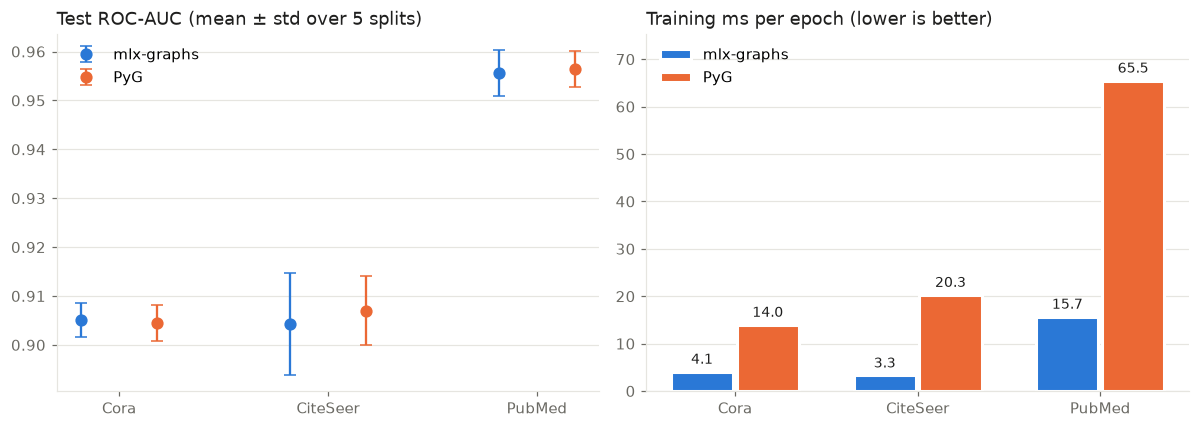

In [21]:
import matplotlib.pyplot as plt

COLORS = {"mlx-graphs": "#2a78d6", "PyG": "#eb6834"}
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"
NAMES = {"cora": "Cora", "citeseer": "CiteSeer", "pubmed": "PubMed"}
FRAMEWORKS = ["mlx-graphs", "PyG"]

fig, (ax_auc, ax_time) = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(DATASETS))
width = 0.36

for i, framework in enumerate(FRAMEWORKS):
    offset = (i - 0.5) * width
    runs_of = results[results["framework"] == framework].groupby("dataset", sort=False)
    auc = runs_of["test_auc"].agg(["mean", "std"]).loc[DATASETS]
    ax_auc.errorbar(
        x + offset,
        auc["mean"],
        yerr=auc["std"],
        fmt="o",
        markersize=7,
        capsize=4,
        color=COLORS[framework],
        label=framework,
    )
    times = summary.xs(framework, level="framework").loc[DATASETS, "train ms/epoch"]
    bars = ax_time.bar(
        x + offset,
        times,
        width - 0.02,
        color=COLORS[framework],
        edgecolor="white",
        linewidth=2,
        label=framework,
    )
    for bar, value in zip(bars, times):
        ax_time.annotate(
            f"{value:.1f}",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            color=INK,
            fontsize=9,
        )

ax_auc.set_title(
    f"Test ROC-AUC (mean ± std over {len(SPLIT_SEEDS)} splits)", loc="left", color=INK
)
ax_time.set_title("Training ms per epoch (lower is better)", loc="left", color=INK)
ax_time.set_ylim(0, summary["train ms/epoch"].max() * 1.15)
for ax in (ax_auc, ax_time):
    ax.set_xticks(x, [NAMES[d] for d in DATASETS])
    ax.legend(frameon=False)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
fig.tight_layout()
plt.show()

These timings were measured on an Apple M5 Pro, with mlx-graphs on the GPU and PyG on the CPU (the number of PyTorch threads is printed above).

**Accuracy.** The two frameworks train the same model to the same accuracy: on every dataset, the test AUC and AP of mlx-graphs and PyG are within the variation between splits, shown by the error bars, and so are the ranking metrics in the table. The models start from different random weights, so the results of a given split differ slightly between the frameworks, as they would between two runs of the same framework.

The ranking metrics are much lower than the AUC. Telling a positive edge from a random negative edge is easy, while finding the few hidden neighbors of a node among all the others is not, and it gets harder as the graph grows: PubMed has the highest AUC but the lowest MRR and Hits@20, since each query ranks almost 20,000 nodes.

**Runtime.** mlx-graphs is faster than PyG on all three datasets, both for training and for evaluation; the speedups are printed above the figure. On graphs this small, an epoch takes milliseconds, so fixed costs, such as the negative sampling on the CPU (in both frameworks) and launching the GPU kernels, weigh a lot in the training time. Timings vary from run to run and from machine to machine, so run the notebook on your own machine to compare.

## Going further

- The same code runs on larger graphs with `AmazonDataset("photo")` or `CoauthorDataset("cs")`; [examples/link_prediction.py](https://github.com/mlx-graphs/mlx-graphs/blob/main/examples/link_prediction.py) is a command-line version of section 2.
- For heterogeneous graphs, such as users and items, `LinkNeighborLoader` takes a `HeteroGraphData` and the supervised edge type, and `to_hetero` turns a homogeneous encoder into a heterogeneous one.
- `LightGCN` is a light-weight model for recommendation, trained with a ranking loss, whose `recommend` method returns the top-$k$ items of a user. The ranking metrics of section 3 evaluate it directly.
- For knowledge graphs, whose edges have types, `mlx_graphs.nn` provides the embedding models `TransE`, `DistMult`, `ComplEx` and `RotatE`, with a `KGTripletLoader` and `test` methods that compute the mean rank and Hits@k.
- `train_test_split_edges` is the older, functional way to split the edges, and `batched_negative_sampling` samples negative edges within each graph of a batch of graphs.